# π0.7, step by step 🎛️
### A steerable generalist: the prompt grows from "what" to "what, how well, how fast, in which control mode, and what it should look like"

**Model:** `Pi07Policy` + `Pi07Runtime` (`src/Halo_VLA/pi_family/pi07.py`), `SubgoalWorldModel` (`world_model.py`) · **source:** Physical Intelligence,
*π0.7: a Steerable Generalist Robotic Foundation Model with Emergent Capabilities* (technical report, April 2026,
[pi.website/blog/pi07](https://www.pi.website/blog/pi07), [PDF](https://www.pi.website/download/pi07.pdf)). Builds on π0.6 and the MEM memory system
(Torne et al., 2026), and keeps π0.5's FAST tokens, knowledge insulation and adaRMSNorm. Read `pi0_step_by_step.ipynb` and `pi05_step_by_step.ipynb` first.

π0, π0.5 and π0.6 are told one thing: a short text task. The π0.7 report's idea is that **richer context lets you train on much more diverse data**,
including slow, sloppy and failed episodes, because the model can be told *how* each episode was performed; at test time you then ask for the good
version. The context `C_t` grows to:

| context | what it carries | training rate | step |
|---|---|---|---|
| task + **subtask** text | what to do now | subtask dropped 30 % when a subgoal is given | 1, 8 |
| **episode metadata** | speed, quality (1-5), mistake flag | all dropped 15 %, each field 5 % | 4 |
| **control mode** | `ee` or `joint` | never dropped | 4 |
| **subgoal images** | what the scene should look like next, from a *world model* | in 25 % of examples (we use 50 %) | 6 |
| **MEM history** | past frames compressed to one frame's tokens, plus past states | history dropped 30 % | 5 |

and the training recipe gains **prompt dropout** (so any subset works at test time, and **classifier-free guidance** becomes possible) and
**training-time real-time chunking** (so a chunk can continue the actions already executing during inference).

| | published π0.7 | this notebook |
|---|---|---|
| backbone | Gemma3 4B VLM (400M vision tower) + MEM video encoder | width 64, 2 layers, plain patch embedding, VQA pre-training |
| action expert | 860M, adaRMSNorm, 50 actions, 5 denoising steps | width 48, adaRMSNorm, 16 actions, 5 steps |
| world model | BAGEL (14B image generation / editing model) | small conditional flow-matching DiT |
| history | up to 6 frames per view, 1 s stride | 4 frames, configurable stride |

> **How to read the results.** Each mechanism is tested in its own small experiment (a model trained on what that experiment needs), because
> at this scale one tiny backbone cannot learn every feature at once, and we found that stacking them all hurts each of them. Every number is
> a single seed on 48-64 unseen scenes: read effects of a few points as noise, large effects as real. Total runtime is about 30 minutes on a
> laptop CPU.

## Step 0: Setup, and demonstrations that differ in *how* they were done

The point world from the earlier notebooks, now with four demonstration **styles**, each labelled with π0.7's episode metadata:

| style | behaviour | speed | quality |
|---|---|---|---|
| `expert` | straight line, fast | fast | 5 |
| `careful` | straight line, slow | slow | 4 |
| `sloppy` | wobbles sideways | slow | 2-3 |
| `mistake` | heads for a wrong object first, then corrects | slow | 1-2, `mistake: true` while detouring |

Traditional behaviour cloning would throw away three of the four (or average them). π0.7 keeps all of them, *labelled*.

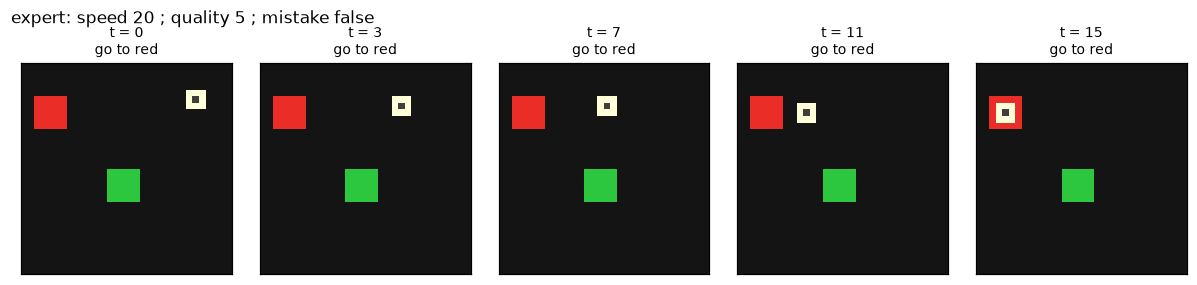

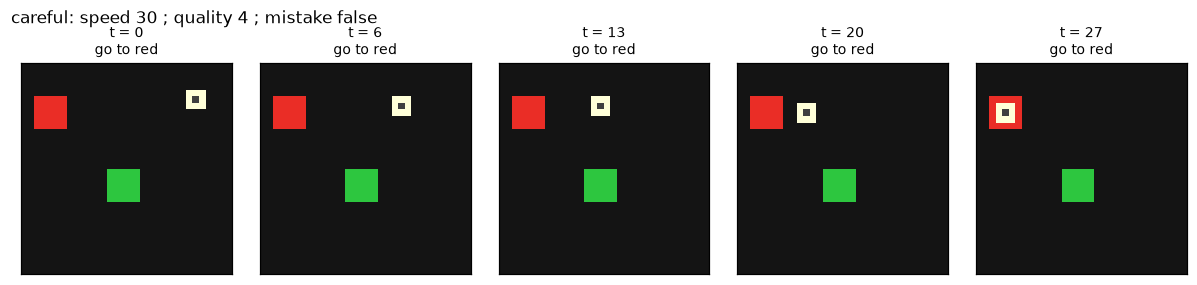

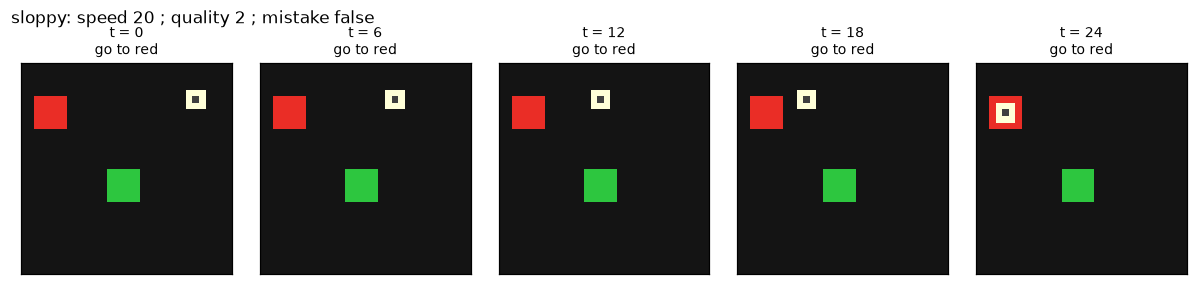

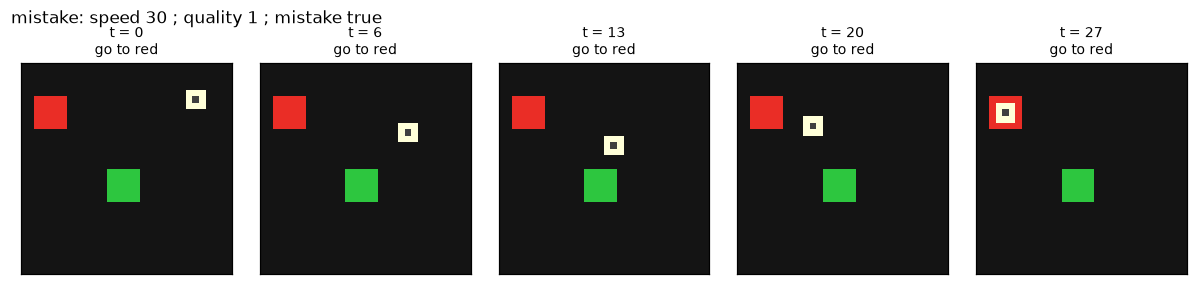

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import pi_kit
pi_kit.setup_paths()
from pi_kit import plots, diagrams as dg

from pi_family import (Pi07Config, Pi07Policy, Pi07Runtime, PiTrainer, FastActionTokenizer, EpisodeMetadata, SubgoalWorldModel,
                       bin_speed, make_attention_mask, split_prefix_suffix_mask)
from pi_family.pretraining import VQAPretrainer
from pi_family.toy import PointWorld, DemoGenerator, ChunkDataset, ClosedLoopEvaluator, make_scenarios, collate

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world = PointWorld()
gen = DemoGenerator(world)

# the same scene demonstrated in the four styles
task = gen.sample_task("reach", np.random.default_rng(11))
for style in ("expert", "careful", "sloppy", "mistake"):
    ep = gen.demo("reach", np.random.default_rng(5), style, task=task)
    data_demo = ChunkDataset([ep], world, 16)
    plots.show_episode(data_demo, ep, title=f"{style}: {ep.metadata.prompt()}")

### 🖼️ Diagram: what goes into the prompt

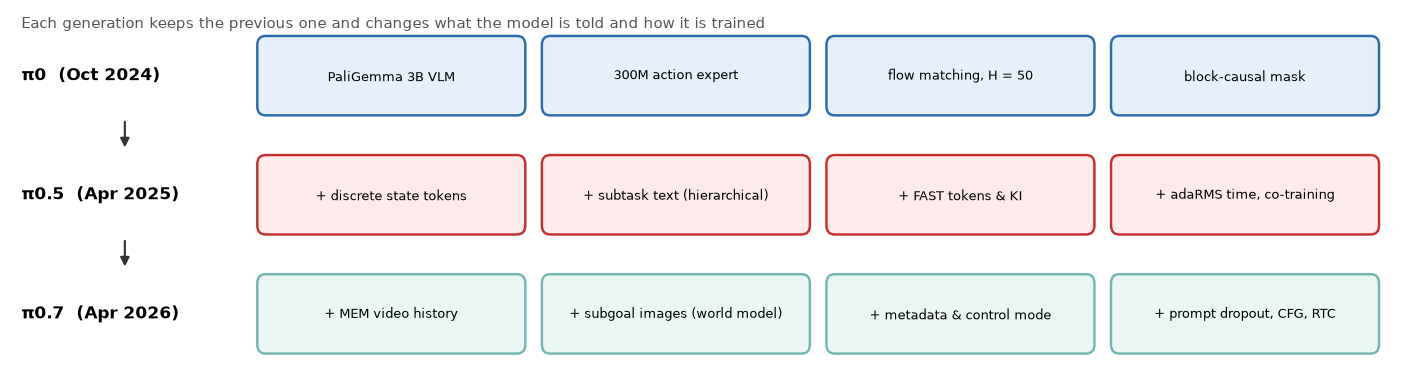

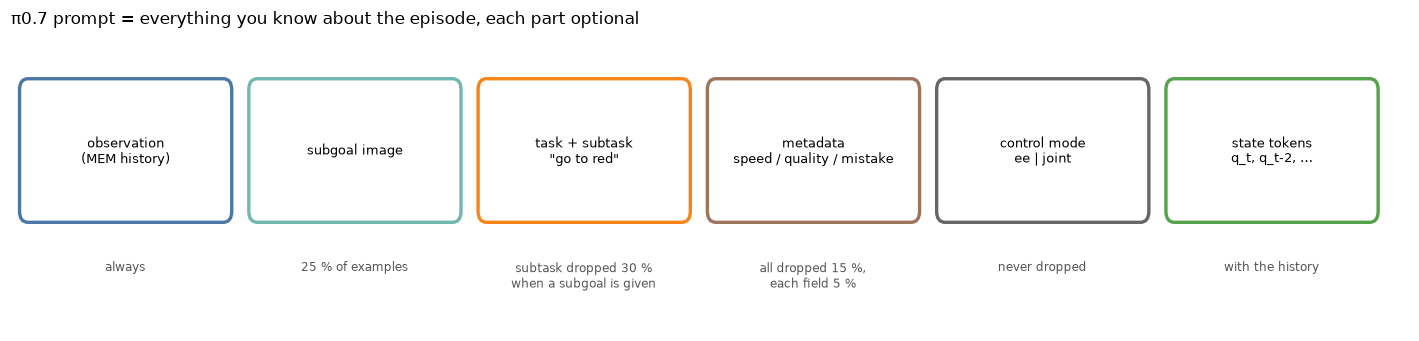

In [2]:
dg.fig_family_overview()
dg.fig_pi07_prompt()

## Step 1: The prompt as tokens

One example becomes this sequence (history of one frame here):

```
[ observation tokens ][ subgoal tokens ] <bos> task go to red ; subtask go to red ; speed 10 ; quality 5 ; mistake false ; control mode ee  <q_t> <sep>
  bidirectional         bidirectional      └──────────────────────── causal text, continuous state token ────────────────────────┘
[ <boa> FAST … <eoa> ]   hidden from the action expert, cross-entropy target       [ a_1 … a_H ]  action expert, adaRMSNorm(τ per token)
```

Compared with π0.5: the language part carries metadata and control mode; the state is a **continuous token** `q_t = Linear(state)` in the backbone
(MEM style) rather than text bins; images come first as bidirectional blocks (observation, then subgoal, which may also read the observation).

task go to blue ; subtask go to blue ; speed 30 ; quality 1 ; mistake true ; control mode ee
{'total': '256,610', 'vision': '21,568', 'backbone': '82,240', 'action_expert': '87,504'} (+ 33,472 in the history encoder's temporal layer)


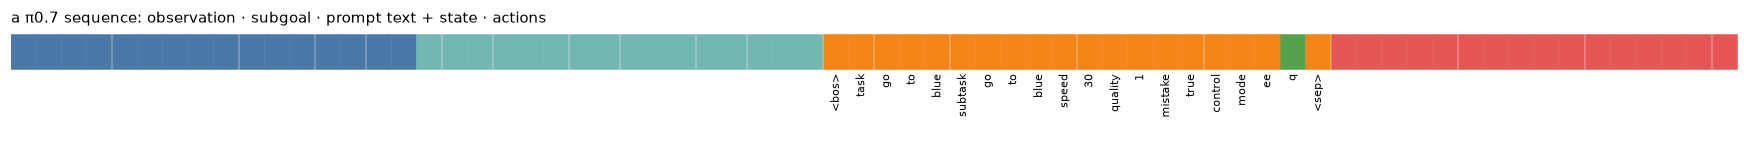

In [3]:
config = Pi07Config(knowledge_insulation=False, history_frames=1)
episodes = gen.dataset(["reach", "collect"], 600, np.random.default_rng(0), styles=("expert", "careful", "sloppy", "mistake"), joint_fraction=0.3)
data = ChunkDataset(episodes, world, config.chunk_size, history_frames=1)
fast = FastActionTokenizer(config.chunk_size, config.action_dim).fit(data.sample(300, np.random.default_rng(1)).actions)
model = Pi07Policy(config, fast)

batch = data.sample(8, np.random.default_rng(3))
print(Pi07Policy.prompt_text(batch.task[0], batch.subtask[0], batch.metadata[0], batch.control_mode[0]))
print({k: f"{v:,}" for k, v in model.parameter_counts().items()}, "(+", f"{sum(p.numel() for p in model.history_encoder.temporal.parameters()):,} in the history encoder's temporal layer)")
with_goal = batch.replace(subgoal_valid=torch.ones(8, dtype=torch.bool))
prefix = model.build_prefix(with_goal, train=False)
suffix = model.build_suffix(with_goal, torch.randn(8, config.chunk_size, 2), torch.rand(8, config.chunk_size))
plots.plot_token_layout(prefix, config.chunk_size, vocab=model.vocab, title="a π0.7 sequence: observation · subgoal · prompt text + state · actions")

## Step 2: Attention, and what the action expert may read

Same rules as π0.5 (block-causal, `ar` bits): the two image blocks are bidirectional, the subgoal block can read the observation, the text is causal,
and the **FAST tokens are hidden from the action expert** during training.

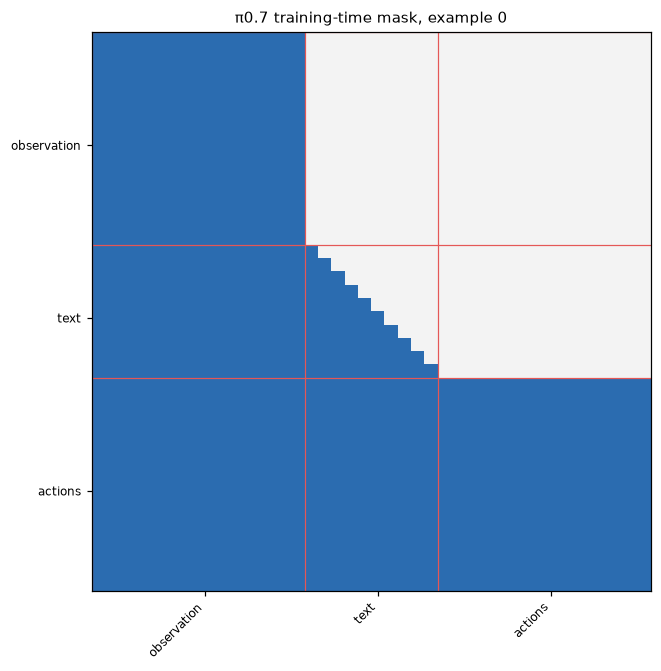

In [4]:
train_prefix = model.build_prefix(batch, train=True)
suffix = model.build_suffix(batch, torch.randn(8, config.chunk_size, 2), torch.rand(8, config.chunk_size))
pm, sm = split_prefix_suffix_mask(train_prefix.ar, train_prefix.valid, train_prefix.action_visible, suffix.ar)
plots.plot_attention_mask(pm, sm, train_prefix, title="π0.7 training-time mask, example 0")

## Step 3: Prompt dropout: every component is optional

During training each component is dropped at the report's rates, so the network learns to act with *any subset* of the context, and (Step 4)
"unconditional" is just "metadata dropped". We check the rates empirically: a large batch, counting what survives.

In [5]:
big = data.sample(4000, np.random.default_rng(5))
big = big.replace(subgoal_valid=torch.ones(4000, dtype=torch.bool))
use_goal, subtasks, metadata, hv, high = model._dropout(big, train=True)
rate = lambda x: float(np.mean(x))
print(f"subgoal image present        : {rate(use_goal.numpy()):.2f}   (config {config.subgoal_probability:.2f}; paper 0.25)")
print(f"subtask kept | subgoal given  : {np.mean([s is not None for s, g in zip(subtasks, use_goal) if g]):.2f}   (paper 0.70)")
print(f"metadata entirely dropped     : {rate([m.is_empty() for m in metadata]):.2f}   (paper 0.15)")
print(f"speed field kept              : {rate([m.speed is not None for m in metadata]):.2f}   (paper 0.85 · 0.95 = 0.81)")
print(f"high-level examples           : {rate(high.numpy()):.2f}   (config {config.high_level_fraction:.2f})")

subgoal image present        : 0.25   (config 0.25; paper 0.25)
subtask kept | subgoal given  : 0.71   (paper 0.70)
metadata entirely dropped     : 0.16   (paper 0.15)
speed field kept              : 0.80   (paper 0.85 · 0.95 = 0.81)
high-level examples           : 0.20   (config 0.20)


## Step 4: Metadata and control mode: *steering*

This is the report's central trick. We train one model on **all four styles and both control modes** (`ee` and `joint`, a fixed linear map between
action spaces), each demonstration carrying its metadata. At test time we ask for different behaviours **by changing the prompt only**:

* `speed 10, quality 5, mistake false`: the behaviour of the best demonstrations (the paper always prompts quality 5, no mistakes, and the
  15th percentile of the episode length for speed);
* `speed 20, quality 4`: a slower, careful run;
* `speed 50, quality 1, mistake true`: ask for the bad version;
* nothing: the average over all styles.

First, stage 0: the same VQA pre-training as in the earlier notebooks, now through the policy's *own* observation path (`encode_observation`),
so the pre-trained perception is the one the policy reads the scene with.

step  1000  loss 3.2576  (text_acc 0.342, flow 0.106, text 2.195)


step  2000  loss 2.7483  (text_acc 0.409, flow 0.089, text 1.860)


step  3000  loss 2.2073  (text_acc 0.518, flow 0.068, text 1.524)


step  4000  loss 2.1928  (text_acc 0.497, flow 0.063, text 1.560)
trained in 212 s


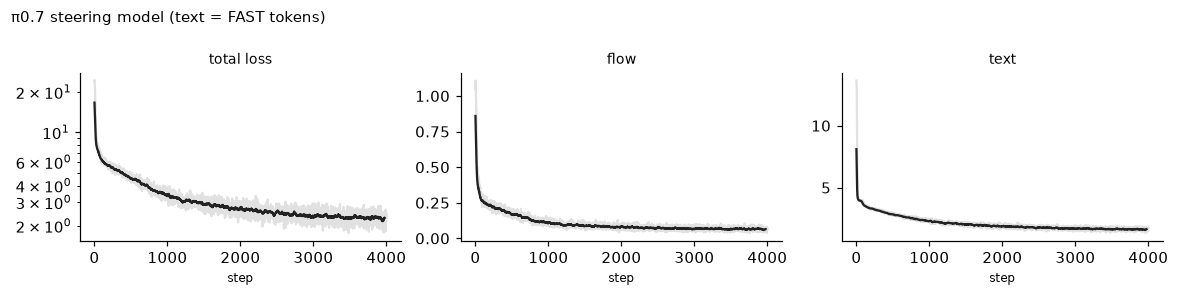

In [6]:
def make_model(cfg, episodes, history_frames=1, history_stride=2, vqa_steps=1500):
    ds = ChunkDataset(episodes, world, cfg.chunk_size, history_frames=history_frames, history_stride=history_stride)
    tok = FastActionTokenizer(cfg.chunk_size, cfg.action_dim, cfg.fast_scale, cfg.fast_max_coefficient, cfg.fast_bpe_merges)
    tok.fit(ds.sample(300, np.random.default_rng(1)).actions)
    torch.manual_seed(0)
    policy = Pi07Policy(cfg, tok)
    VQAPretrainer(policy, world).fit(vqa_steps)
    return policy, ds

steer_cfg = Pi07Config(knowledge_insulation=False, history_frames=1, subgoal_probability=0.0, max_rtc_delay=0, high_level_fraction=0.0)
steer_eps = gen.dataset(["reach"], 5000, np.random.default_rng(0), styles=("expert", "careful", "sloppy", "mistake"),
                        style_weights=[0.4, 0.2, 0.2, 0.2], joint_fraction=0.3)
steer, steer_data = make_model(steer_cfg, steer_eps)
hist = PiTrainer(steer, steer_data, batch_size=64, lr=2e-3, grad_clip=10.0).fit(4000, log_every=1000)
print(f"trained in {hist.seconds:.0f} s")
plots.plot_loss(hist, keys=("flow", "text"), title="π0.7 steering model (text = FAST tokens)")

fast · q5              {'success': 1.0, 'wrong_first': 0.0, 'steps': 11.0, 'path': 0.484}
slow · q4              {'success': 1.0, 'wrong_first': 0.0, 'steps': 19.6, 'path': 0.476}
slow · q1 · mistake    {'success': 0.438, 'wrong_first': 0.031, 'steps': 32.9, 'path': 0.843}
no metadata            {'success': 1.0, 'wrong_first': 0.0, 'steps': 15.2, 'path': 0.483}


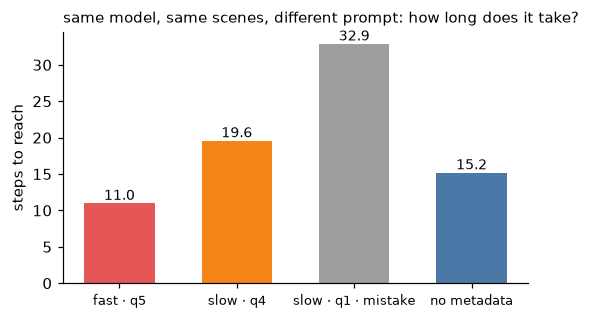

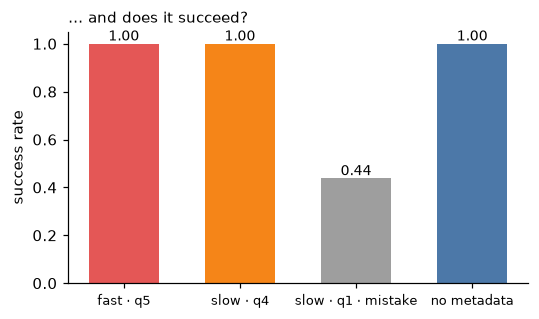

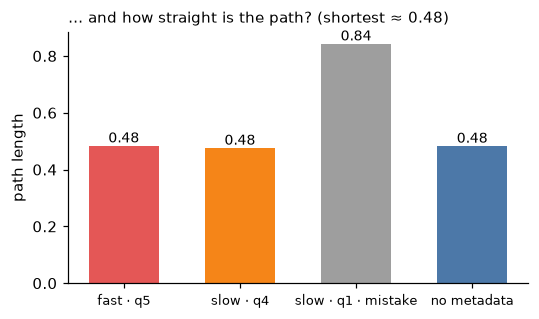

In [7]:
evaluator = ClosedLoopEvaluator(world, 16, exec_horizon=8, max_steps=70, history_frames=1)
expert_lengths = sorted(e.active_steps for e in steer_eps if e.style.name == "expert")
fast_speed = bin_speed(int(np.percentile(expert_lengths, 15)))          # the paper's recipe: 15th percentile of the episode length
prompts = {"fast · q5": EpisodeMetadata(fast_speed, 5, False), "slow · q4": EpisodeMetadata(20, 4, False),
           "slow · q1 · mistake": EpisodeMetadata(50, 1, True), "no metadata": EpisodeMetadata()}
reach = lambda meta, mode="ee": make_scenarios(gen, "reach", 64, seed=123, metadata=meta, control_mode=mode)
results = {k: evaluator.run(lambda b, c: steer.act(b), reach(m)) for k, m in prompts.items()}
for k, r in results.items():
    print(f"{k:22s}", r.summary())
plots.bar_compare({k: r.summary()["steps"] for k, r in results.items()}, "steps to reach", "same model, same scenes, different prompt: how long does it take?",
                  colors=["#e45756", "#f58518", "#9e9e9e", "#4c78a8"], fmt="{:.1f}")
plots.bar_compare({k: r.success_rate for k, r in results.items()}, "success rate", "… and does it succeed?", ylim=(0, 1.05), colors=["#e45756", "#f58518", "#9e9e9e", "#4c78a8"])
plots.bar_compare({k: r.summary()["path"] for k, r in results.items()}, "path length", "… and how straight is the path? (shortest ≈ 0.48)", colors=["#e45756", "#f58518", "#9e9e9e", "#4c78a8"])

In [8]:
# same prompts, joint-space control: one model, two action spaces, chosen by a word in the prompt
r_joint = evaluator.run(lambda b, c: steer.act(b), reach(prompts["fast · q5"], "joint"))
print("joint-space control, fast · q5:", r_joint.summary())
# what happens if the control mode word lies? joint-space actions executed as end-effector displacements
liar = evaluator.run(lambda b, c: steer.act(b.replace(control_mode=["joint"] * b.size)), reach(prompts["fast · q5"], "ee"))
print("prompted 'joint' but robot is 'ee':", liar.summary())

joint-space control, fast · q5: {'success': 1.0, 'wrong_first': 0.0, 'steps': 11.2, 'path': 0.483}


prompted 'joint' but robot is 'ee': {'success': 0.891, 'wrong_first': 0.016, 'steps': 21.9, 'path': 0.57}


The wrong control-mode word costs time (more steps) rather than the task: in our toy the joint and end-effector action spaces are related by a
fixed 2×2 matrix close to the identity, so the mismatch is a mild distortion; with a stronger mismatch, or an arm where joint and Cartesian
commands are unrelated, it would fail outright. The point is that the word really selects the action space.

### Classifier-free guidance on the metadata

Because metadata is randomly dropped in training, the same network also models the **unconditional** distribution `π(a | o, C \ metadata)`.
Each denoising step can then extrapolate away from it:

$$\tilde v = v(a \mid C) + \beta\,\big(v(a \mid C) - v(a \mid C_{\text{uncond}})\big)$$

The paper uses β ∈ {1.3, 1.7, 2.2} on the metadata for dexterous tasks, which exaggerates "fast, high quality, no mistakes".

β = 0.0  {'success': 1.0, 'wrong_first': 0.0, 'steps': 11.7, 'path': 0.481}
β = 1.3  {'success': 0.984, 'wrong_first': 0.0, 'steps': 9.6, 'path': 0.496}
β = 2.2  {'success': 0.953, 'wrong_first': 0.0, 'steps': 8.5, 'path': 0.501}


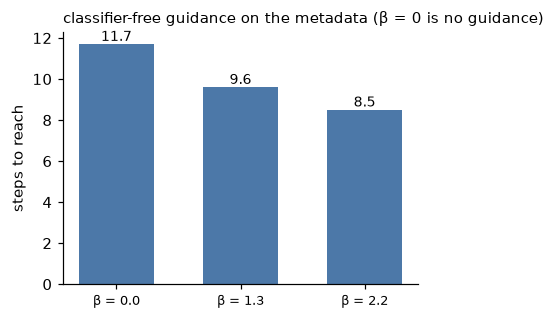

In [9]:
cfg_runs = {f"β = {b}": evaluator.run(lambda x, c, b=b: steer.act(x, cfg_scale=b), reach(prompts["fast · q5"])) for b in (0.0, 1.3, 2.2)}
for k, r in cfg_runs.items():
    print(f"{k:8s}", r.summary())
plots.bar_compare({k: r.summary()["steps"] for k, r in cfg_runs.items()}, "steps to reach", "classifier-free guidance on the metadata (β = 0 is no guidance)", fmt="{:.1f}")

## Step 5: MEM history: memory in a fixed token budget

Some tasks cannot be solved from the current picture. In our **marked** task the target is outlined for the first two steps only; afterwards all objects
look alike, and the robot (re-planning every 4 steps) must *remember* which one was marked.

π0.7 handles history with the MEM video encoder: every frame goes through the same patch encoder; then a small temporal transformer mixes **each
patch location across time** and the output at the current frame is kept. So any number of past frames costs the *same number of tokens* as one:
"compressed to the same number of tokens as a single frame". Past states are extra tokens too (we leave them off: see the note below).

In [10]:
mem_cfg = Pi07Config(history_frames=4, history_stride=4)
mem_policy = Pi07Policy(mem_cfg, fast)
frames = torch.rand(2, 4, 3, 32, 32)
one = mem_policy.history_encoder(frames[:, :1])
four = mem_policy.history_encoder(frames, torch.tensor([[True] * 4, [True, True, False, False]]))
print("tokens from 1 frame :", tuple(one.shape), "= (B, patches, width)")
print("tokens from 4 frames:", tuple(four.shape), " ← same count; missing frames (episode start, dropout) are masked")

tokens from 1 frame : (2, 16, 64) = (B, patches, width)
tokens from 4 frames: (2, 16, 64)  ← same count; missing frames (episode start, dropout) are masked


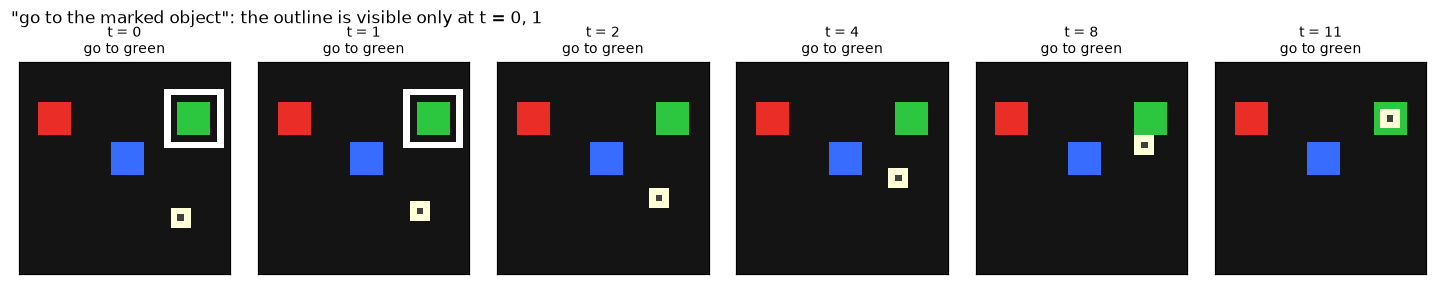

no history (1 frame)               {'success': 0.766, 'wrong_first': 0.172, 'steps': 15.8, 'path': 0.503}


MEM history (4 frames, stride 4)   {'success': 0.766, 'wrong_first': 0.031, 'steps': 12.9, 'path': 0.479}


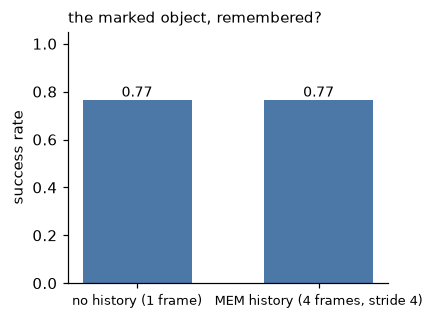

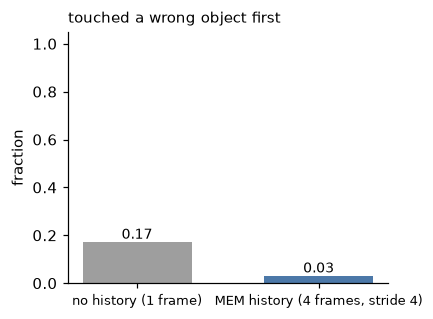

In [11]:
marked_eps = gen.dataset(["marked"], 4000, np.random.default_rng(0))
show_ep = marked_eps[0]
plots.show_episode(ChunkDataset([show_ep], world, 16), show_ep, steps=[0, 1, 2, 4, 8, show_ep.active_steps], title='"go to the marked object": the outline is visible only at t = 0, 1')

mem_results = {}
for name, T, stride in [("no history (1 frame)", 1, 2), ("MEM history (4 frames, stride 4)", 4, 4)]:
    cfg = Pi07Config(knowledge_insulation=False, history_frames=T, history_stride=stride, subgoal_probability=0.0, max_rtc_delay=0,
                     high_level_fraction=0.0, history_dropout=0.0, train_fast_tokens=False)
    pol, ds = make_model(cfg, marked_eps, T, stride)
    PiTrainer(pol, ds, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000)
    ev = ClosedLoopEvaluator(world, 16, exec_horizon=4, max_steps=50, history_frames=T, history_stride=stride)
    scen = make_scenarios(gen, "marked", 64, seed=123)
    mem_results[name] = ev.run(lambda b, c: pol.act(b), scen)
    print(f"{name:34s}", mem_results[name].summary())
plots.bar_compare({k: r.success_rate for k, r in mem_results.items()}, "success rate", "the marked object, remembered?", ylim=(0, 1.05))
plots.bar_compare({k: r.summary()["wrong_first"] for k, r in mem_results.items()}, "fraction", "touched a wrong object first", ylim=(0, 1.05), colors=["#9e9e9e", "#4c78a8"])

**What to take from this.** The history model should touch wrong objects less often. Success itself is similar here: a single frame is not
as blind as it looks (after the first chunk the robot is already heading toward the target, and its position carries information), and a longer history
is harder to learn from demonstrations. The paper reports memory-requiring tasks (e.g. remembering what has already been done in a long task)
where specialists without memory fail outright.

> **A note on past states and the "copycat" problem.** MEM also feeds *past robot states* as tokens. When we turned them on, success on the plain
> reach task collapsed in closed loop even though the training loss looked fine: from the past states the model can read the current *velocity* and
> learn "keep doing what the last steps did", which is right on demonstrations and wrong the moment the policy's own errors take it somewhere new.
> That is the classic imitation-learning copycat failure. The flag `Pi07Config.use_state_history` is therefore off here; the report's models
> train on far more diverse data and add dropout on history, which protects against it.

## Step 6: Subgoal images from a world model

Text is a coarse way to say what you want: *"open the fridge"* does not say how to grasp the handle. A **subgoal image** shows the desired
near-future scene. π0.7 gets them from a lightweight **world model** `g_ψ(o_t, ℓ̂_t, m)`, a generative model initialised from BAGEL (14B) that takes the
current images and the subtask text and *edits* the scene into what it should look like when the subtask is done, trained with flow matching on
`g*_t = o_{t_end}`, the last frame of the segment. Its web-scale pre-training is how knowledge the robot data lacks reaches the policy: through pictures.

Ours is a small DiT (patches of `[noisy goal ‖ current image]` + subtask words, adaRMSNorm for τ).

world model trained in 124 s, 636,912 parameters


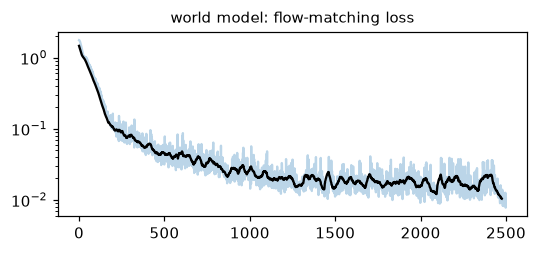

In [12]:
goal_eps = gen.dataset(["reach", "collect"], 4000, np.random.default_rng(0))
goal_data = ChunkDataset(goal_eps, world, 16, history_frames=1)
torch.manual_seed(0)
wm = SubgoalWorldModel()
opt = torch.optim.AdamW(wm.parameters(), lr=1e-3)
wm_rng, wm_losses, t0 = np.random.default_rng(3), [], time.time()
for step in range(2500):
    for g in opt.param_groups:
        g["lr"] = 1e-3 * min(1.0, (step + 1) / 50)
    obs, texts, goal = goal_data.sample_world_model(64, wm_rng)
    loss = wm.compute_loss(obs, texts, goal)
    opt.zero_grad(); loss.backward(); opt.step()
    wm_losses.append(loss.item())
print(f"world model trained in {time.time() - t0:.0f} s, {sum(p.numel() for p in wm.parameters()):,} parameters")
plt.figure(figsize=(5, 2.4)); plt.plot(wm_losses, alpha=0.3); plt.plot(np.convolve(wm_losses, np.ones(25) / 25, mode="valid"), color="k")
plt.yscale("log"); plt.title("world model: flow-matching loss", fontsize=10); plt.tight_layout(); plt.show()

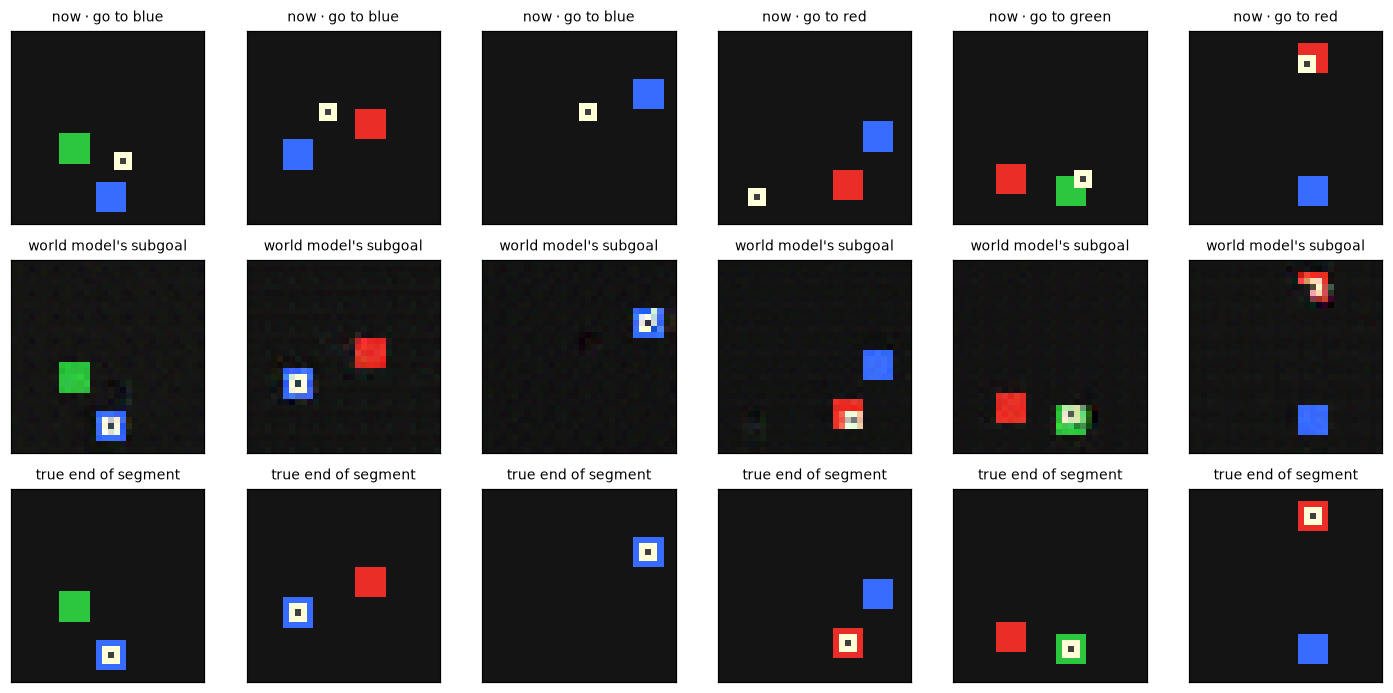

MSE to the true subgoal: generated 0.0016   |   just copying the current image 0.0080


In [13]:
obs, texts, goal = goal_data.sample_world_model(6, np.random.default_rng(21))
generated = wm.sample(obs, texts)
fig, axes = plt.subplots(3, 6, figsize=(13, 6.4))
for i in range(6):
    plots.show_image(axes[0, i], obs[i], f"now · {texts[i]}")
    plots.show_image(axes[1, i], generated[i], "world model's subgoal")
    plots.show_image(axes[2, i], goal[i], "true end of segment")
plt.tight_layout(); plt.show()
obs, texts, goal = goal_data.sample_world_model(128, np.random.default_rng(22))
print(f"MSE to the true subgoal: generated {(wm.sample(obs, texts) - goal).pow(2).mean():.4f}   |   just copying the current image {(obs - goal).pow(2).mean():.4f}")

Now the **subgoal-conditioned policy**. As in the report, subgoal images are added to a fraction of the training examples (we use 50 %, the paper 25 %);
with the subgoal present the action prediction becomes close to an *inverse dynamics* problem (what action takes the image I see to the image I am
shown?), which is why the paper finds the model "trains significantly faster when given the subgoal images". At run time `Pi07Runtime` implements the
report's Algorithm 1: ask the world model for a subgoal whenever the subtask changes or Δ steps have passed, and feed it to the policy.

We evaluate the *same* trained policy with and without subgoals.

trained in 206 s


reach · no subgoal             {'success': 0.042, 'wrong_first': 0.062, 'steps': 51.0, 'path': 0.606}
reach · world-model subgoal    {'success': 0.958, 'wrong_first': 0.021, 'steps': 12.8, 'path': 0.498}
collect · no subgoal           {'success': 0.0, 'wrong_first': 0.042, 'steps': nan, 'path': nan}
collect · world-model subgoal  {'success': 0.958, 'wrong_first': 0.083, 'steps': 29.8, 'path': 1.193}


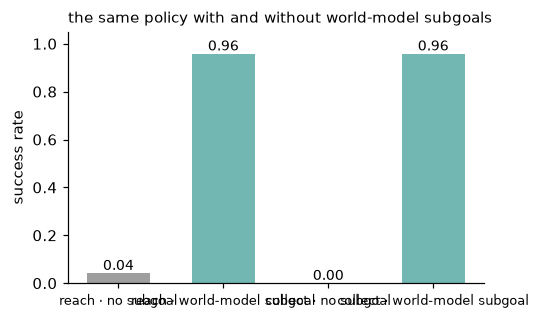

In [14]:
goal_cfg = Pi07Config(knowledge_insulation=False, history_frames=1, subgoal_probability=0.5, max_rtc_delay=0, high_level_fraction=0.0, train_fast_tokens=False)
goal_policy, goal_ds = make_model(goal_cfg, goal_eps)
ghist = PiTrainer(goal_policy, goal_ds, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3500)
print(f"trained in {ghist.seconds:.0f} s")
meta = EpisodeMetadata(10, 5, False)
goal_eval = ClosedLoopEvaluator(world, 16, exec_horizon=8, max_steps=70, history_frames=1)
goal_results = {}
for kind in ("reach", "collect"):
    scen = make_scenarios(gen, kind, 48, seed=123, metadata=meta)
    goal_results[f"{kind} · no subgoal"] = goal_eval.run(lambda b, c: goal_policy.act(b), scen)
    goal_results[f"{kind} · world-model subgoal"] = goal_eval.run(Pi07Runtime(goal_policy, meta, world_model=wm), scen)
for k, r in goal_results.items():
    print(f"{k:30s}", r.summary())
plots.bar_compare({k: r.success_rate for k, r in goal_results.items()}, "success rate", "the same policy with and without world-model subgoals", ylim=(0, 1.05),
                  colors=["#9e9e9e", "#72b7b2"] * 2)

### Seeing the subgoals during a run

The runtime keeps the latest subgoal and refreshes it when the subtask changes ("go to red" → "go to blue" in a `collect` task). Below: the scene at
four moments of one run, with the subgoal the policy was shown.

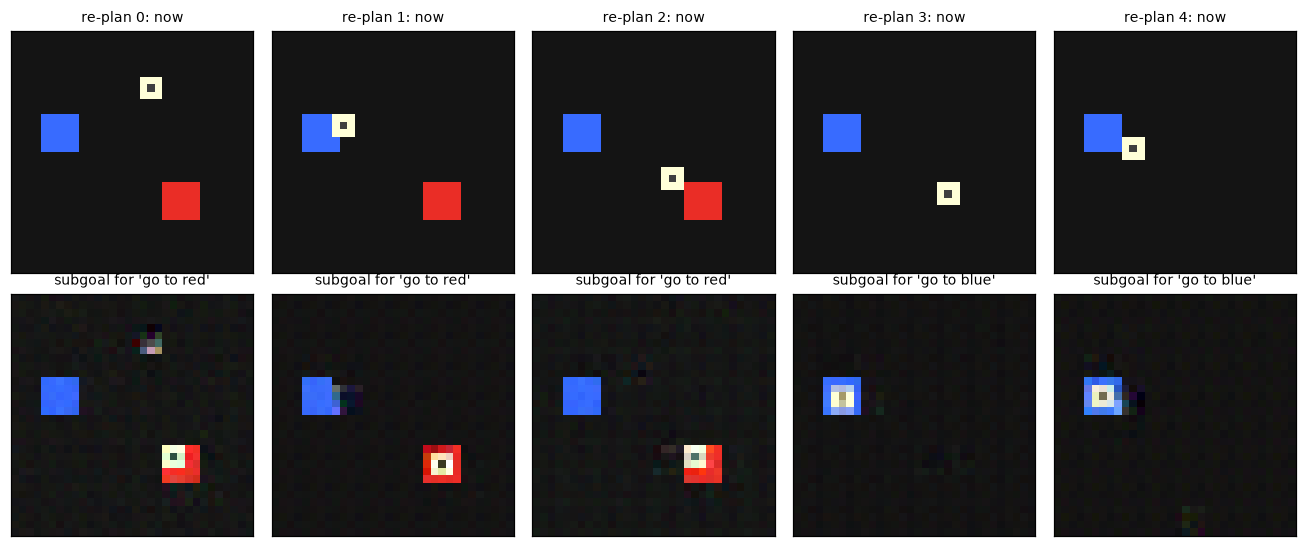

run: {'success': 1.0, 'wrong_first': 0.0, 'steps': 35.0, 'path': 1.478}


In [15]:
scen = make_scenarios(gen, "collect", 1, seed=77, metadata=meta)
runtime = Pi07Runtime(goal_policy, meta, world_model=wm)
shots = []
def record(batch, committed):
    chunk = runtime(batch, committed)
    shots.append((batch.images[0].clone(), runtime.subgoal[0].clone(), runtime.subtasks[0]))
    return chunk
res = goal_eval.run(record, scen)
n = min(len(shots), 5)
fig, axes = plt.subplots(2, n, figsize=(2.4 * n, 5.0))
for i in range(n):
    plots.show_image(axes[0, i], shots[i][0], f"re-plan {i}: now")
    plots.show_image(axes[1, i], shots[i][1], f"subgoal for '{shots[i][2]}'")
plt.tight_layout(); plt.show()
print("run:", res.summary())

## Step 7: The high-level policy and the full runtime

The subtask text comes from a **high-level policy**: the same architecture trained to map (task, observations, history of subtasks) to the next
subtask (`high_level_fraction` of the examples have the subtask as their text target), exactly as in `pi05_step_by_step.ipynb`. In the report
it can also be a human *coaching* the robot step by step. `Pi07Runtime(..., high_level=True)` closes the loop of Algorithm 1:

```
subtask ←  high-level policy (or a coach)       subgoal ← world model(observation, subtask, metadata)
chunk   ←  π0.7(observations, {task, subtask, subgoal, metadata, control mode})       execute the first Ĥ actions, repeat
```

The report runs these three at different rates in separate threads; `Pi07Runtime` is synchronous for clarity.

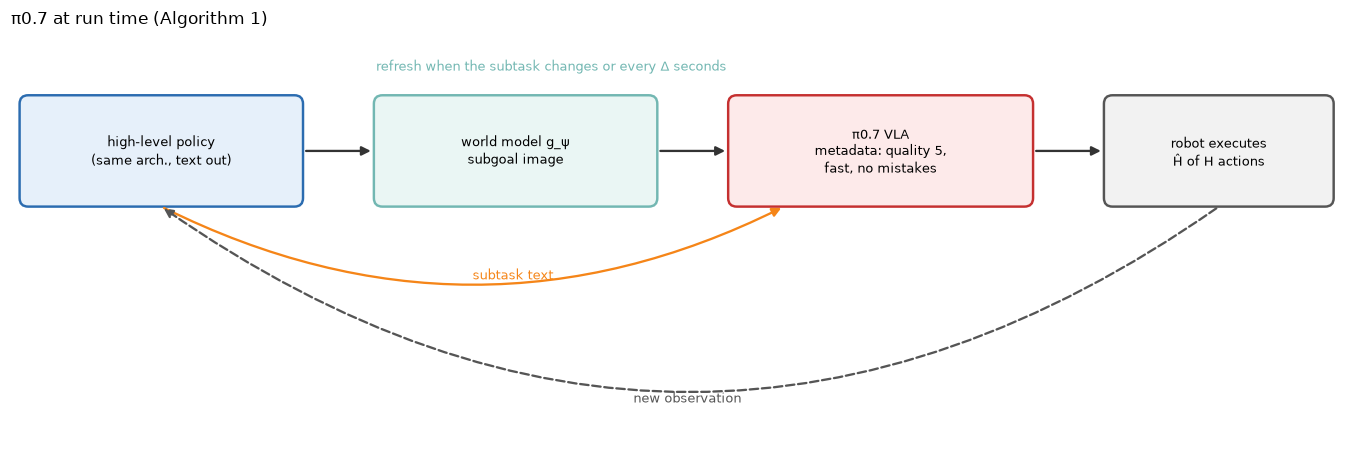

In [16]:
dg.fig_pi07_runtime()

## Step 8: Training-time real-time chunking (RTC)

A real robot keeps moving while the model thinks: by the time a new chunk arrives, `d` steps of the old one have already been executed. The new
chunk must **continue** those actions rather than jump. π0.7 trains for this: with `d ~ U{0…max_delay}` the first `d` actions of the chunk are given
*clean* (flow time τ = 0 for those tokens, which is why adaRMSNorm conditions *per token*) and excluded from the loss; the model learns to generate the
rest consistently with them. At run time the actions already executing are passed in as the committed prefix.

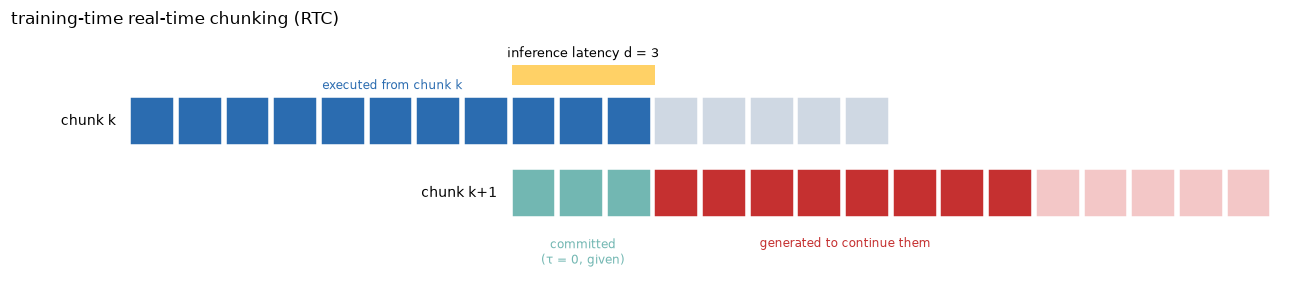

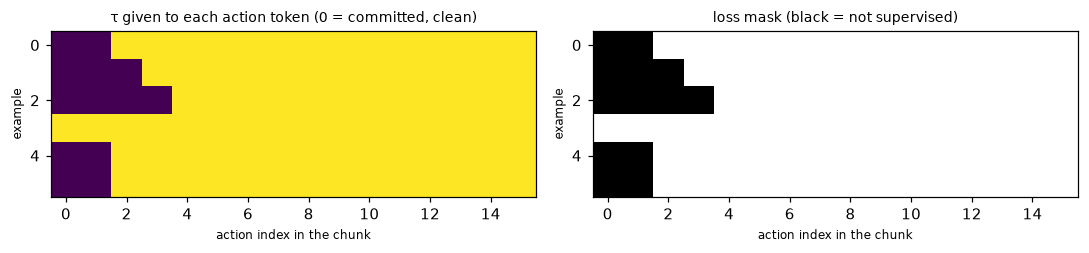

In [17]:
dg.fig_rtc()
rtc_model = Pi07Policy(Pi07Config(max_rtc_delay=4), fast)
time_in, loss_mask = rtc_model.prepare_flow_inputs(torch.zeros(6, 16, 2), torch.full((6, 16), 0.7))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.4))
axes[0].imshow(time_in.numpy(), cmap="viridis", aspect="auto"); axes[0].set_title("τ given to each action token (0 = committed, clean)", fontsize=9)
axes[1].imshow(loss_mask.numpy(), cmap="gray", aspect="auto", vmin=0, vmax=1); axes[1].set_title("loss mask (black = not supervised)", fontsize=9)
for a in axes:
    a.set_xlabel("action index in the chunk", fontsize=8); a.set_ylabel("example", fontsize=8)
plt.tight_layout(); plt.show()

Does it help in our world? We train two models on the plain reach task, one without RTC and one with `max_delay = 3`, and run them with a simulated
inference delay of 0 and 3 steps, each with and without passing the committed actions.

In [18]:
rtc_eps = gen.dataset(["reach"], 4000, np.random.default_rng(0))
rtc_scen = make_scenarios(gen, "reach", 64, seed=123, metadata=meta)
rtc_ev = ClosedLoopEvaluator(world, 16, exec_horizon=8, max_steps=50, history_frames=1)
rtc_table = {}
for name, d in (("trained without RTC", 0), ("trained with RTC (d ≤ 3)", 3)):
    cfg = Pi07Config(knowledge_insulation=False, history_frames=1, subgoal_probability=0.0, max_rtc_delay=d, high_level_fraction=0.0, train_fast_tokens=False)
    pol, ds = make_model(cfg, rtc_eps)
    PiTrainer(pol, ds, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000)
    for delay in (0, 3):
        rtc_table[(name, delay, "plain")] = rtc_ev.run(lambda b, c: pol.act(b), rtc_scen, delay=delay).success_rate
        rtc_table[(name, delay, "committed")] = rtc_ev.run(lambda b, c: pol.act(b, committed=c), rtc_scen, delay=delay, pass_committed=True).success_rate
for k, v in rtc_table.items():
    print(f"{k[0]:28s} delay {k[1]}  {k[2]:9s} success {v:.2f}")

trained without RTC          delay 0  plain     success 1.00
trained without RTC          delay 0  committed success 1.00
trained without RTC          delay 3  plain     success 0.97
trained without RTC          delay 3  committed success 0.97
trained with RTC (d ≤ 3)     delay 0  plain     success 0.34
trained with RTC (d ≤ 3)     delay 0  committed success 0.34
trained with RTC (d ≤ 3)     delay 3  plain     success 0.09
trained with RTC (d ≤ 3)     delay 3  committed success 0.12


**Reading this honestly.** In this toy world a delay of 3 steps barely matters: the old chunk keeps moving the point along a smooth line and the
next one picks up from the new image, so the *untrained-for-delay* model does fine, and the RTC-trained model pays for the harder objective (a fraction of
every chunk is not supervised, and the per-token τ pattern is a different input distribution than at inference with no delay). RTC solves a problem of
**real arms**: at 50 Hz with 100+ ms inference, the old and new chunks can disagree by a visible jerk. To make the effect show here, increase `delay`
(and the chunk length) in the evaluator, or add a stiff dynamics model that punishes discontinuities.

## Step 9: Does it still look at the world? 🔬

Two controls on the steering model: **black image** (should collapse) and **swapped colour word** (should follow the new instruction).

In [19]:
import copy
scen = reach(prompts["fast · q5"])
blind = evaluator.run(lambda b, c: steer.act(b.replace(images=torch.zeros_like(b.images), history=torch.zeros_like(b.history))), scen)   # the policy reads b.history
swapped = []
for s in scen:
    other = [c for c in s.scene.objects if c != s.targets[0]][0]
    s2 = copy.copy(s); s2.task, s2.targets, s2.alternatives = f"go to {other}", [other], [other]
    swapped.append(s2)
sw = evaluator.run(lambda b, c: steer.act(b), swapped)
print(f"normal {results['fast · q5'].success_rate:.2f} | swapped colour word {sw.success_rate:.2f} | black image {blind.success_rate:.2f}")

normal 1.00 | swapped colour word 1.00 | black image 0.06


## Step 10: Recap and exercises

```
observation (MEM history → one frame of tokens) ┐
subgoal image (from the world model)            ├─► VLM backbone ─► FAST tokens (CE, hidden from the expert)
task · subtask · metadata · control mode (text) ┤                    └► subtask text (high-level policy)
state q_t (continuous token)                    ┘        │ keys/values (detach() with knowledge insulation)
noise ε, per-token τ  ─►  action expert (adaRMSNorm) ─► v_θ ─► Euler (5 steps) [+ CFG on metadata] ─► chunk
every context component randomly dropped in training; first d actions clean + unsupervised (RTC)
```

**What this toy shows:** metadata and control mode steer one model's speed, quality and action space (Step 4); a subgoal picture from a world model
carries a policy that fails without it (Step 6); history reduces wrong-object visits (Step 5). **What it does not show:** RTC's benefit (Step 8), memory-only
tasks at scale, or the open-world generalisation that is the report's headline: that needs web-scale pre-training, many robots and a 5B model.

### 🧪 Exercises
1. Train the steering model on `expert` demonstrations only and prompt `slow · q1`: can the model produce bad behaviour it never saw? (The paper's answer is subtle: compositional generalisation needs diversity.)
2. Change `subgoal_probability` to 0.25 (the paper's value) in Step 6 and retrain: how does success *without* subgoals change?
3. Set `knowledge_insulation=True` in the steering model. Compare success and training loss: what does the VQA-pre-trained backbone gain or lose?
4. Turn on `use_state_history=True` for the marked task and evaluate on the plain reach task from Step 4: reproduce the copycat failure from the note in Step 5.
5. In the RTC experiment pass `delay=8` (use `exec_horizon=8`, a chunk of 16): does the picture change?